# CaloDiffusion — Pion Outlier and Layer-Profile Closeout

**Purpose:** investigate the three controlled pion fidelity runs without generating any new showers.

This notebook examines:
1. Response outliers (unusually high and low deposited-energy response).
2. Radial outliers and unusually large native-cell deposits.
3. Longitudinal/layer-profile deviations.
4. Extreme-event frequencies across all three generation seeds.
5. Whether the same native detector cells repeatedly receive large deposits.

## Inputs
Upload the three existing pion fidelity ZIP files for generation seeds **20260110, 20260111 and 20260112**.

## Fixed analysis convention
- Pion analysis threshold: **0.01 GeV (10 MeV)**.
- Native geometry: 533 cells in 7 active layers.
- Reference sample: 300 events per energy, reused from the same fixed partition.
- Generated sample: 600 events per energy per seed; 1,800 per energy pooled across seeds.
- Scale-only sample: 300 events per energy, reused because donor selection was fixed.

The notebook chooses one reference and one scale-only array per energy, rather than accidentally counting the same arrays three times.

## Interpretation cautions
- Reference percentile envelopes are estimated from only 300 events per energy. A 1st–99th percentile envelope is a **screening tool**, not a physical acceptance boundary.
- A statistical outlier is not automatically a physically impossible shower or a model defect.
- The 0.1 GeV and 1 GeV cell-deposit thresholds below are **diagnostic thresholds**, not changes to the 10 MeV analysis cutoff.
- The scale-only baseline uses donors from the 32.768 GeV calibration group, rescaled by factors 0.25, 1 and 2 for the three target energies. Interpret it as a simple control, not as a fully energy-conditioned competing generator.
- Reference/checkpoint training and selection independence is still unverified in the run manifests.

No checkpoint loading, retraining or new shower generation is performed here.

## 1. Imports and analysis settings

In [ ]:
import io, json, zipfile, hashlib, os, math, textwrap
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wasserstein_distance
from IPython.display import display, Markdown

ENERGIES = [8.192, 32.768, 65.536]
ENERGY_LABELS = {E: f"{E:.3f}GeV" for E in ENERGIES}
ANALYSIS_CUT_GEV = 0.01
EXPECTED_SEEDS = [20260110, 20260111, 20260112]
EXPECTED_PARTITION_SEED = 20261120
EXPECTED_BASELINE_SEED = 20261102
EXPECTED_ANALYSIS_SEED = 20261103
EXPECTED_REVISION = "00ebcc3534fc25eee0fe15361483833e0bca34e7"
EXPECTED_REFERENCE_SHA256 = "3b947455ce76178708b85364f108273ece694e7dbade282a65d2766f13c25ade"
EXPECTED_CHECKPOINT_SHA256 = "77fa86ea1ce6fefe90685019ad45ce13408a2ee33d36833221b4187d0bde82e4"
CELL_DIAGNOSTIC_THRESHOLDS_GEV = [0.1, 1.0]
REFERENCE_ENVELOPE = (0.01, 0.99)
ROBUST_Z_THRESHOLD = 3.5
RADIAL_BAND_EDGES = np.array([0, 10, 30, 50, 100, 200, 400, 600, 1000, 2000], dtype=float)
OUTPUT_DIR = Path("/content/pion_outlier_layer_closeout")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Pion analysis cutoff:", ANALYSIS_CUT_GEV, "GeV")
print("Expected generation seeds:", EXPECTED_SEEDS)
print("Output directory:", OUTPUT_DIR)

Pion analysis cutoff: 0.01 GeV
Expected generation seeds: [20260110, 20260111, 20260112]
Output directory: /content/pion_outlier_layer_closeout


## 2. Upload the three fidelity ZIP files

In [ ]:
from google.colab import files
uploaded = files.upload()
zip_uploads = {name: payload for name, payload in uploaded.items() if name.lower().endswith(".zip")}
if len(zip_uploads) != 3:
    raise ValueError(f"Upload exactly three pion fidelity ZIP files. Found {len(zip_uploads)} ZIP files.")
print("Uploaded:")
for name in zip_uploads:
    print(" -", name)

Saving validated_calo_controlled_pion_partition20261120_generation20260110_20261111T062300492793Z_fidelity_20261111T064128440045Z.zip to validated_calo_controlled_pion_partition20261120_generation20260110_20261111T062300492793Z_fidelity_20261111T064128440045Z.zip
Saving validated_calo_controlled_pion_partition20261120_generation20260111_20261111T064222710362Z_fidelity_20261111T065944965723Z.zip to validated_calo_controlled_pion_partition20261120_generation20260111_20261111T064222710362Z_fidelity_20261111T065944965723Z.zip
Saving validated_calo_controlled_pion_partition20261120_generation20260112_20261111T070027866892Z_fidelity_20261111T071834882647Z.zip to validated_calo_controlled_pion_partition20261120_generation20260112_20261111T070027866892Z_fidelity_20261111T071834882647Z.zip
Uploaded:
 - validated_calo_controlled_pion_partition20261120_generation20260110_20261111T062300492793Z_fidelity_20261111T064128440045Z.zip
 - validated_calo_controlled_pion_partition20261120_generation202601

## 3. Read manifests and verify controlled-run compatibility

In [ ]:
def find_member(zf, suffix):
    matches = [n for n in zf.namelist() if n.endswith(suffix)]
    if len(matches) != 1:
        raise ValueError(f"Expected exactly one member ending with {suffix!r}; found {len(matches)}")
    return matches[0]

def read_json_member(zf, suffix):
    return json.loads(zf.read(find_member(zf, suffix)))

def read_csv_member(zf, suffix):
    return pd.read_csv(io.BytesIO(zf.read(find_member(zf, suffix))))

def read_npz_member(zf, suffix):
    member = find_member(zf, suffix)
    with np.load(io.BytesIO(zf.read(member)), allow_pickle=False) as data:
        return {k: data[k].copy() for k in data.files}

runs = {}
for filename, payload in zip_uploads.items():
    zf = zipfile.ZipFile(io.BytesIO(payload))
    manifest = read_json_member(zf, "manifest.json")
    seed = int(manifest["seed_streams"]["generation_seed"])
    if seed in runs:
        raise ValueError(f"Duplicate generation seed {seed}.")
    runs[seed] = {"filename": filename, "payload": payload, "zip": zf, "manifest": manifest}

if sorted(runs) != sorted(EXPECTED_SEEDS):
    raise ValueError(f"Expected seeds {EXPECTED_SEEDS}; found {sorted(runs)}")

compat_rows = []
base_manifest = runs[EXPECTED_SEEDS[0]]["manifest"]
for seed in EXPECTED_SEEDS:
    m = runs[seed]["manifest"]
    checks = {
        "generation_seed": seed,
        "partition_seed_fixed": m["seed_streams"]["partition_seed"] == EXPECTED_PARTITION_SEED,
        "baseline_seed_fixed": m["seed_streams"]["baseline_seed"] == EXPECTED_BASELINE_SEED,
        "analysis_seed_fixed": m["seed_streams"]["analysis_seed"] == EXPECTED_ANALYSIS_SEED,
        "partition_hash_matches": m["partition_sha256"]["pion"] == base_manifest["partition_sha256"]["pion"],
        "donor_hashes_match": m["scale_donor_sha256"]["pion"] == base_manifest["scale_donor_sha256"]["pion"],
        "checkpoint_matches": m["checkpoints"]["pion"]["sha256"] == EXPECTED_CHECKPOINT_SHA256,
        "reference_matches": m["reference_files"]["pion"]["sha256"] == EXPECTED_REFERENCE_SHA256,
        "repository_revision_matches": m["revision"] == EXPECTED_REVISION,
        "analysis_cut_matches": np.isclose(m["analysis_cut_GeV_overrides"]["pion"], ANALYSIS_CUT_GEV),
        "reference_unseen_claimed": bool(m["reference_is_unseen_by_checkpoint"]),
    }
    gates = json.loads(runs[seed]["zip"].read(find_member(runs[seed]["zip"], "validation_gates.json")))
    checks["all_technical_gates_passed"] = all(bool(g.get("passed", False)) for g in gates)
    checks["technical_gate_count"] = len(gates)
    compat_rows.append(checks)

compatibility = pd.DataFrame(compat_rows)
display(compatibility)

hard_checks = [c for c in compatibility.columns if c not in ["generation_seed", "reference_unseen_claimed", "technical_gate_count"]]
if not compatibility[hard_checks].all().all():
    raise RuntimeError("At least one run-compatibility check failed. Do not interpret pooled results until resolved.")

print("\nPASS: Same checkpoint, reference file, reference partition, donors, cutoff and source revision.")
print("NOTE: reference_is_unseen_by_checkpoint is false; provenance remains unresolved.")

,generation_seed,partition_seed_fixed,baseline_seed_fixed,analysis_seed_fixed,partition_hash_matches,donor_hashes_match,checkpoint_matches,reference_matches,repository_revision_matches,analysis_cut_matches,reference_unseen_claimed,all_technical_gates_passed,technical_gate_count
0,20260110,True,True,True,True,True,True,True,True,True,False,True,16
1,20260111,True,True,True,True,True,True,True,True,True,False,True,16
2,20260112,True,True,True,True,True,True,True,True,True,False,True,16



PASS: Same checkpoint, reference file, reference partition, donors, cutoff and source revision.
NOTE: reference_is_unseen_by_checkpoint is false; provenance remains unresolved.


## 4. Compare the actual partition and donor CSVs

In [ ]:
partition_tables = {}
donor_tables = {}
for seed in EXPECTED_SEEDS:
    zf = runs[seed]["zip"]
    partition_tables[seed] = read_csv_member(zf, "tables/pion_event_partitions.csv")
    donor_tables[seed] = {
        E: read_csv_member(zf, f"tables/pion_{E:.3f}GeV_scale_donors.csv")
        for E in ENERGIES
    }

reference_partitions_identical = all(
    partition_tables[EXPECTED_SEEDS[0]].equals(partition_tables[s])
    for s in EXPECTED_SEEDS[1:]
)
donors_identical = all(
    donor_tables[EXPECTED_SEEDS[0]][E].equals(donor_tables[s][E])
    for s in EXPECTED_SEEDS[1:] for E in ENERGIES
)

print("Reference partition CSVs identical:", reference_partitions_identical)
print("Scale-only donor CSVs identical:", donors_identical)
assert reference_partitions_identical, "Reference partition tables differ."
assert donors_identical, "Scale-only donor selections differ."

display(partition_tables[EXPECTED_SEEDS[0]].groupby(["stratum", "partition"]).size().rename("n_events").reset_index())
# Record how the scale-only reference showers are constructed.
donor_details = []
for E in ENERGIES:
    d = donor_tables[EXPECTED_SEEDS[0]][E]
    donor_details.append({
        "target_energy_GeV": E,
        "source_energy_values_GeV": sorted(d["source_energy"].unique().tolist()),
        "scale_factors": sorted(d["factor"].unique().tolist()),
        "n_donors": len(d),
    })
donor_details = pd.DataFrame(donor_details)
print("Scale-only donor construction:")
display(donor_details)


Reference partition CSVs identical: True
Scale-only donor CSVs identical: True


,stratum,partition,n_events
0,32.768GeV,calibration,300
1,32.768GeV,pilot,150
2,32.768GeV,test,300
3,65.536GeV,calibration,300
4,65.536GeV,pilot,150
5,65.536GeV,test,300
6,8.192GeV,calibration,300
7,8.192GeV,pilot,150
8,8.192GeV,test,300


Scale-only donor construction:


,target_energy_GeV,source_energy_values_GeV,scale_factors,n_donors
0,8.192,[32.768],[0.25],300
1,32.768,[32.768],[1.0],300
2,65.536,[32.768],[2.0],300


## 5. Reconstruct the native-cell geometry map

In [ ]:
geometry_by_seed = {
    seed: read_json_member(runs[seed]["zip"], "pion_geometry.json")
    for seed in EXPECTED_SEEDS
}
geometry = geometry_by_seed[EXPECTED_SEEDS[0]]
for seed in EXPECTED_SEEDS[1:]:
    if geometry_by_seed[seed] != geometry:
        raise ValueError("Pion geometry differs between runs.")

layer_ids = list(map(int, geometry["layer_ids"]))
n_angles = list(map(int, geometry["n_angles"]))
radial_edges_by_layer = geometry["radial_edges"]

cell_rows = []
layer_rows = []
offset = 0
for layer_ordinal, (layer_id, n_ang, edges) in enumerate(zip(layer_ids, n_angles, radial_edges_by_layer)):
    edges = np.asarray(edges, dtype=float)
    n_radial = len(edges) - 1
    start = offset
    stop = start + n_ang * n_radial
    layer_rows.append({
        "layer_ordinal": layer_ordinal,
        "layer_id": layer_id,
        "n_angles": n_ang,
        "n_radial": n_radial,
        "native_start": start,
        "native_stop_exclusive": stop,
        "native_cells": n_ang * n_radial,
    })
    # Native ordering: layer -> angular bin -> radial bin.
    for angle in range(n_ang):
        for radial in range(n_radial):
            cell_rows.append({
                "native_index": offset + angle * n_radial + radial,
                "layer_ordinal": layer_ordinal,
                "layer_id": layer_id,
                "angle_index": angle,
                "radial_bin": radial,
                "r_low_XML": edges[radial],
                "r_high_XML": edges[radial + 1],
                "r_center_XML": 0.5 * (edges[radial] + edges[radial + 1]),
            })
    offset = stop

cell_map = pd.DataFrame(cell_rows)
layer_map = pd.DataFrame(layer_rows)
assert len(cell_map) == 533, f"Expected 533 native cells; found {len(cell_map)}"
assert offset == 533
print("Native cells:", len(cell_map))
print("Active layers:", len(layer_map))
display(layer_map)

Native cells: 533
Active layers: 7


,layer_ordinal,layer_id,n_angles,n_radial,native_start,native_stop_exclusive,native_cells
0,0,0,1,8,0,8,8
1,1,1,10,10,8,108,100
2,2,2,10,10,108,208,100
3,3,3,1,5,208,213,5
4,4,12,10,15,213,363,150
5,5,13,10,16,363,523,160
6,6,14,1,10,523,533,10


## 6. Load reference, generated and scale-only native arrays

In [ ]:
# Each NPZ contains native arrays in physical GeV, an incident-energy vector and event IDs.
# Reference and scale-only arrays are loaded once and verified identical in the other ZIPs.

def load_sample(zf, energy, role, run_id=None):
    if role == "reference":
        suffix = f"arrays/pion_{energy:.3f}GeV_reference_run-1.npz"
    elif role == "scale_only":
        suffix = f"arrays/pion_{energy:.3f}GeV_scale_only_run-1.npz"
    elif role == "generator":
        suffix = f"arrays/pion_{energy:.3f}GeV_generator_run{run_id}.npz"
    else:
        raise ValueError(role)
    data = read_npz_member(zf, suffix)
    if not {"native", "energy", "event_id"}.issubset(data):
        raise ValueError(f"Unexpected NPZ schema for {suffix}: {list(data)}")
    native = np.asarray(data["native"], dtype=np.float64)
    energies = np.asarray(data["energy"], dtype=np.float64).reshape(-1)
    event_ids = np.asarray(data["event_id"]).astype(str).reshape(-1)
    if native.ndim != 2 or native.shape[1] != 533:
        raise ValueError(f"Unexpected native array shape: {native.shape}")
    if len(native) != len(energies) or len(native) != len(event_ids):
        raise ValueError("Native array, energy and event-ID row counts differ.")
    return {"native": native, "energy": energies, "event_id": event_ids, "run_id": run_id}

samples = {}
for E in ENERGIES:
    first_zf = runs[EXPECTED_SEEDS[0]]["zip"]
    ref0 = load_sample(first_zf, E, "reference")
    scale0 = load_sample(first_zf, E, "scale_only")

    # Verify the fixed reference and baseline arrays are literally identical.
    for seed in EXPECTED_SEEDS[1:]:
        zf = runs[seed]["zip"]
        ref_check = load_sample(zf, E, "reference")
        scale_check = load_sample(zf, E, "scale_only")
        assert np.array_equal(ref0["native"], ref_check["native"])
        assert np.array_equal(ref0["event_id"], ref_check["event_id"])
        assert np.array_equal(scale0["native"], scale_check["native"])
        assert np.array_equal(scale0["event_id"], scale_check["event_id"])

    samples[(E, "reference", "reference")] = ref0
    samples[(E, "scale_only", "scale_only")] = scale0

    for seed in EXPECTED_SEEDS:
        zf = runs[seed]["zip"]
        g0 = load_sample(zf, E, "generator", run_id=0)
        g1 = load_sample(zf, E, "generator", run_id=1)
        gen = {
            "native": np.concatenate([g0["native"], g1["native"]], axis=0),
            "energy": np.concatenate([g0["energy"], g1["energy"]]),
            "event_id": np.concatenate([g0["event_id"], g1["event_id"]]),
            "run_id": np.concatenate([
                np.zeros(len(g0["energy"]), dtype=int),
                np.ones(len(g1["energy"]), dtype=int)
            ]),
        }
        samples[(E, "generator", seed)] = gen

    print(f"{E:.3f} GeV: reference={len(ref0['energy'])}, "
          f"generator/seed={len(samples[(E, 'generator', EXPECTED_SEEDS[0])]['energy'])}, "
          f"scale-only={len(scale0['energy'])}")

8.192 GeV: reference=300, generator/seed=600, scale-only=300
32.768 GeV: reference=300, generator/seed=600, scale-only=300
65.536 GeV: reference=300, generator/seed=600, scale-only=300


## 7. Calculate event-level metrics from native cells

In [ ]:
cell_layer_ord = cell_map["layer_ordinal"].to_numpy(dtype=int)
cell_layer_id = cell_map["layer_id"].to_numpy(dtype=int)
cell_angle = cell_map["angle_index"].to_numpy(dtype=int)
cell_radial_bin = cell_map["radial_bin"].to_numpy(dtype=int)
cell_r_low = cell_map["r_low_XML"].to_numpy(dtype=float)
cell_r_high = cell_map["r_high_XML"].to_numpy(dtype=float)
cell_r_center = cell_map["r_center_XML"].to_numpy(dtype=float)

radial_band_ids = np.digitize(cell_r_center, RADIAL_BAND_EDGES, right=False) - 1
radial_band_ids = np.clip(radial_band_ids, 0, len(RADIAL_BAND_EDGES) - 2)
radial_band_labels = [
    f"{RADIAL_BAND_EDGES[i]:g}-{RADIAL_BAND_EDGES[i+1]:g}"
    for i in range(len(RADIAL_BAND_EDGES) - 1)
]


def calculate_event_metrics(native, energy_GeV, event_ids, method, seed_label, run_ids=None):
    native = np.asarray(native, dtype=np.float64)
    n = len(native)
    kept = np.where(np.isfinite(native) & (native >= ANALYSIS_CUT_GEV), native, 0.0)
    total = kept.sum(axis=1)
    valid_total = total > 0
    response = np.divide(total, energy_GeV, out=np.full(n, np.nan), where=np.asarray(energy_GeV) > 0)
    hits = (kept > 0).sum(axis=1)
    occupancy = hits / 533.0

    layer_energy = np.column_stack([
        kept[:, cell_layer_ord == j].sum(axis=1)
        for j in range(len(layer_ids))
    ])
    layer_fraction = np.divide(
        layer_energy, total[:, None],
        out=np.zeros_like(layer_energy), where=total[:, None] > 0
    )
    layer_ord_grid = np.arange(len(layer_ids), dtype=float)
    depth = np.divide(
        layer_energy @ layer_ord_grid, total,
        out=np.full(n, np.nan), where=total > 0
    )

    r_mean = np.divide(
        kept @ cell_r_center, total,
        out=np.full(n, np.nan), where=total > 0
    )
    r_rms = np.sqrt(np.divide(
        kept @ (cell_r_center ** 2), total,
        out=np.full(n, np.nan), where=total > 0
    ))
    r_sigma = np.sqrt(np.divide(
        (kept * (cell_r_center[None, :] - r_mean[:, None]) ** 2).sum(axis=1),
        total, out=np.full(n, np.nan), where=total > 0
    ))

    max_idx = np.argmax(kept, axis=1)
    max_cell_energy = kept[np.arange(n), max_idx]

    radial_band_energy = np.column_stack([
        kept[:, radial_band_ids == b].sum(axis=1)
        for b in range(len(radial_band_labels))
    ])
    radial_band_fraction = np.divide(
        radial_band_energy, total[:, None],
        out=np.zeros_like(radial_band_energy), where=total[:, None] > 0
    )

    rows = []
    for i in range(n):
        j = int(max_idx[i])
        row = {
            "energy_GeV": float(energy_GeV[i]),
            "method": method,
            "seed": str(seed_label),
            "generation_run": int(run_ids[i]) if run_ids is not None else -1,
            "sample_index": i,
            "event_id": str(event_ids[i]),
            "deposited_GeV": float(total[i]),
            "response": float(response[i]),
            "nhits": int(hits[i]),
            "occupancy": float(occupancy[i]),
            "depth_layer": float(depth[i]) if np.isfinite(depth[i]) else np.nan,
            "r_mean_XML": float(r_mean[i]) if np.isfinite(r_mean[i]) else np.nan,
            "r_rms_XML": float(r_rms[i]) if np.isfinite(r_rms[i]) else np.nan,
            "r_sigma_XML": float(r_sigma[i]) if np.isfinite(r_sigma[i]) else np.nan,
            "max_cell_energy_GeV": float(max_cell_energy[i]),
            "max_cell_index": j,
            "max_cell_layer_id": int(cell_layer_id[j]),
            "max_cell_layer_ordinal": int(cell_layer_ord[j]),
            "max_cell_angle_index": int(cell_angle[j]),
            "max_cell_radial_bin": int(cell_radial_bin[j]),
            "max_cell_r_low_XML": float(cell_r_low[j]),
            "max_cell_r_high_XML": float(cell_r_high[j]),
        }
        for k in range(len(layer_ids)):
            row[f"layer_fraction_{k}"] = float(layer_fraction[i, k])
            row[f"layer_energy_{k}_GeV"] = float(layer_energy[i, k])
        for b, label in enumerate(radial_band_labels):
            row[f"radial_fraction_{label}"] = float(radial_band_fraction[i, b])
            row[f"radial_energy_{label}_GeV"] = float(radial_band_energy[i, b])
        rows.append(row)
    return pd.DataFrame(rows), {
        "kept": kept,
        "layer_energy": layer_energy,
        "layer_fraction": layer_fraction,
        "radial_band_energy": radial_band_energy,
        "radial_band_fraction": radial_band_fraction,
    }

metric_frames = []
profile_arrays = {}
for (E, method, seed_label), sample in samples.items():
    run_ids = sample.get("run_id", None)
    frame, arrays = calculate_event_metrics(
        sample["native"], sample["energy"], sample["event_id"],
        method, seed_label, run_ids
    )
    metric_frames.append(frame)
    profile_arrays[(E, method, seed_label)] = arrays

event_metrics = pd.concat(metric_frames, ignore_index=True)
print("Event-level records:", len(event_metrics))
display(event_metrics.groupby(["energy_GeV", "method", "seed"]).size().rename("n").reset_index().head(30))

Event-level records: 7200


,energy_GeV,method,seed,n
0,8.192,generator,20260110,600
1,8.192,generator,20260111,600
2,8.192,generator,20260112,600
3,8.192,reference,reference,300
4,8.192,scale_only,scale_only,300
5,32.768,generator,20260110,600
6,32.768,generator,20260111,600
7,32.768,generator,20260112,600
8,32.768,reference,reference,300
9,32.768,scale_only,scale_only,300


## 8. Cross-check reconstructed observables against the saved fidelity table

In [ ]:
# Verify our native-array calculations reproduce the observable table from the first run.
first_zf = runs[EXPECTED_SEEDS[0]]["zip"]
stored_obs = read_csv_member(first_zf, "tables/pion_all_fidelity_observables.csv")
recomputed = event_metrics[
    ((event_metrics.method == "reference") & (event_metrics.seed == "reference")) |
    ((event_metrics.method == "generator") & (event_metrics.seed == str(EXPECTED_SEEDS[0]))) |
    ((event_metrics.method == "scale_only") & (event_metrics.seed == "scale_only"))
].copy()

stored_subset = stored_obs[stored_obs.method.isin(["reference", "generator", "scale_only"])].copy()
# Restrict to matching run and sample rows using event IDs and method.
checks = []
for method, seed_label in [("reference", "reference"), ("generator", str(EXPECTED_SEEDS[0])), ("scale_only", "scale_only")]:
    left = recomputed[(recomputed.method == method) & (recomputed.seed == seed_label)]
    right = stored_subset[stored_subset.method == method].copy()
    if method == "generator":
        right = right[right.run.isin([0, 1])]
    right = right.rename(columns={"r_rms": "r_rms_XML"})
    compare = left.merge(right, on="event_id", suffixes=("_new", "_stored"), validate="one_to_one")
    for col in ["deposited_GeV", "response", "occupancy", "depth_layer", "r_rms_XML"]:
        delta = np.max(np.abs(compare[col + "_new"] - compare[col + "_stored"])) if len(compare) else np.nan
        checks.append({"method": method, "observable": col, "n_matched": len(compare), "max_abs_difference": delta})

reconstruction_check = pd.DataFrame(checks)
display(reconstruction_check)
if reconstruction_check["n_matched"].min() == 0:
    raise RuntimeError("Could not match recomputed observables to saved event table.")
if (reconstruction_check["max_abs_difference"] > 5e-4).any():
    print("WARNING: Some reconstructed observables differ from the saved table. Investigate units/cutoff/geometry.")
else:
    print("PASS: Reconstructed native-array observables agree with saved fidelity observables.")

,method,observable,n_matched,max_abs_difference
0,reference,deposited_GeV,900,9.183437e-07
1,reference,response,900,2.802562e-08
2,reference,occupancy,900,8.326673e-17
3,reference,depth_layer,900,3.018423e-08
4,reference,r_rms_XML,900,1.234848e-05
5,generator,deposited_GeV,1800,2.126797e-06
6,generator,response,1800,3.245234e-08
7,generator,occupancy,1800,8.326673e-17
8,generator,depth_layer,1800,2.999311e-08
9,generator,r_rms_XML,1800,1.256229e-05


PASS: Reconstructed native-array observables agree with saved fidelity observables.


## 9. Response, occupancy, depth and radial summaries

In [ ]:
METRICS = ["deposited_GeV", "response", "occupancy", "depth_layer", "r_mean_XML", "r_rms_XML", "r_sigma_XML", "max_cell_energy_GeV"]
QUANTILES = [0.01, 0.05, 0.50, 0.95, 0.99, 1.0]
summary_rows = []
for (E, method, seed_label), group in event_metrics.groupby(["energy_GeV", "method", "seed"]):
    for metric in METRICS:
        x = group[metric].dropna().to_numpy(dtype=float)
        if len(x) == 0:
            continue
        q = np.quantile(x, QUANTILES)
        summary_rows.append({
            "energy_GeV": E, "method": method, "seed": seed_label,
            "observable": metric, "n": len(x),
            "mean": float(np.mean(x)), "std": float(np.std(x, ddof=1)) if len(x)>1 else 0.0,
            "q01": q[0], "q05": q[1], "median": q[2], "q95": q[3], "q99": q[4], "maximum": q[5]
        })
summary = pd.DataFrame(summary_rows)
display(summary[(summary.observable == "response") | (summary.observable == "r_rms_XML")])

,energy_GeV,method,seed,observable,n,mean,std,q01,q05,median,q95,q99,maximum
1,8.192,generator,20260110,response,600,0.657239,0.164057,0.294775,0.390995,0.649266,0.936538,1.069333,1.211092
5,8.192,generator,20260110,r_rms_XML,600,238.834209,123.646204,57.156599,90.932844,215.413334,467.692061,595.837358,996.545564
9,8.192,generator,20260111,response,600,0.667633,0.178146,0.317804,0.402614,0.659293,0.987678,1.103710,1.347932
13,8.192,generator,20260111,r_rms_XML,600,237.127235,122.803167,50.277356,80.184305,214.620584,471.804504,604.194480,786.134210
17,8.192,generator,20260112,response,600,0.656338,0.164959,0.310920,0.408936,0.645407,0.940856,1.098629,1.327108
21,8.192,generator,20260112,r_rms_XML,600,241.480022,118.645618,55.034160,90.911499,218.459325,475.316604,599.281697,702.128070
25,8.192,reference,reference,response,300,0.673007,0.159276,0.355695,0.424742,0.662337,0.920835,1.086496,1.207259
29,8.192,reference,reference,r_rms_XML,300,244.651162,121.973751,45.953540,88.531448,221.610528,464.915213,575.202403,707.334378
33,8.192,scale_only,scale_only,response,300,0.746301,0.119229,0.482925,0.562125,0.746661,0.928263,1.063969,1.175588
37,8.192,scale_only,scale_only,r_rms_XML,300,181.365652,79.668420,37.297672,61.986243,166.824445,315.253339,379.954749,491.716846


## 10. Define outlier flags using the fixed reference sample

In [ ]:
# Empirical reference envelopes: q01-q99 for each energy and observable.
# These are descriptive screens, not hard physical limits.
OUTLIER_METRICS = ["response", "occupancy", "depth_layer", "r_rms_XML", "max_cell_energy_GeV"]
reference_thresholds = {}
for E in ENERGIES:
    ref = event_metrics[(event_metrics.energy_GeV == E) & (event_metrics.method == "reference")]
    reference_thresholds[E] = {}
    for metric in OUTLIER_METRICS:
        q01, q99 = ref[metric].quantile([0.01, 0.99]).to_numpy()
        reference_thresholds[E][metric] = (float(q01), float(q99))

flagged_frames = []
for E in ENERGIES:
    gen = event_metrics[(event_metrics.energy_GeV == E) & (event_metrics.method == "generator")].copy()
    for metric in OUTLIER_METRICS:
        q01, q99 = reference_thresholds[E][metric]
        safe = metric.replace(".", "_")
        gen[f"{safe}_below_ref_q01"] = gen[metric] < q01
        gen[f"{safe}_above_ref_q99"] = gen[metric] > q99
    flag_cols = [c for c in gen.columns if c.endswith("_below_ref_q01") or c.endswith("_above_ref_q99")]
    gen["n_reference_envelope_flags"] = gen[flag_cols].sum(axis=1)
    gen["any_reference_envelope_flag"] = gen["n_reference_envelope_flags"] > 0
    flagged_frames.append(gen)

generator_flagged = pd.concat(flagged_frames, ignore_index=True)
outlier_candidates = generator_flagged[generator_flagged.any_reference_envelope_flag].copy()
print("Generated showers with at least one reference-envelope flag:", len(outlier_candidates), "/", len(generator_flagged))
display(outlier_candidates.sort_values("n_reference_envelope_flags", ascending=False).head(20)[[
    "energy_GeV", "seed", "generation_run", "event_id", "response", "occupancy", "depth_layer", "r_rms_XML", "max_cell_energy_GeV", "max_cell_index", "n_reference_envelope_flags"
]])

Generated showers with at least one reference-envelope flag: 596 / 5400


,energy_GeV,seed,generation_run,event_id,response,occupancy,depth_layer,r_rms_XML,max_cell_energy_GeV,max_cell_index,n_reference_envelope_flags
4676,65.536,20260111,1,gen:pion:65.536GeV:1:176,0.491346,0.026266,5.882548,25.673479,30.348259,523,5
3106,32.768,20260112,0,gen:pion:32.768GeV:0:106,1.598272,0.080675,5.905099,42.030157,46.757999,523,5
2236,32.768,20260110,1,gen:pion:32.768GeV:1:136,1.122816,0.146341,5.416534,43.146988,14.269816,523,4
3871,65.536,20260110,0,gen:pion:65.536GeV:0:271,1.111711,0.236398,5.515393,96.291578,17.913443,523,4
466,8.192,20260110,1,gen:pion:8.192GeV:1:166,1.211092,0.041276,5.632819,140.167003,3.595040,523,4
3824,65.536,20260110,0,gen:pion:65.536GeV:0:224,0.500754,0.185741,5.616628,89.125235,13.630389,523,4
3803,65.536,20260110,0,gen:pion:65.536GeV:0:203,1.075701,0.187617,4.946661,20.500943,19.224779,363,4
4100,65.536,20260110,1,gen:pion:65.536GeV:1:200,1.501098,0.230769,4.000717,32.605563,17.595436,333,4
2477,32.768,20260111,0,gen:pion:32.768GeV:0:77,0.041350,0.024390,4.909678,26.082204,0.673803,523,4
3605,65.536,20260110,0,gen:pion:65.536GeV:0:5,0.007140,0.018762,2.113683,22.438221,0.236817,158,4


## 11. Robust-Z screening (additional exploratory view)

In [ ]:
# Robust Z = 0.6745 * (x - reference median) / MAD.
# MAD=0 is handled as NaN. This is a screening aid, especially for skewed distributions.
ROBUST_METRICS = ["response", "depth_layer", "r_rms_XML", "max_cell_energy_GeV"]
robust_frames = []
for E in ENERGIES:
    ref = event_metrics[(event_metrics.energy_GeV == E) & (event_metrics.method == "reference")]
    gen = event_metrics[(event_metrics.energy_GeV == E) & (event_metrics.method == "generator")].copy()
    for metric in ROBUST_METRICS:
        med = float(ref[metric].median())
        mad = float(np.median(np.abs(ref[metric].to_numpy() - med)))
        if mad > 0:
            gen[f"robust_z_{metric}"] = 0.67448975 * (gen[metric] - med) / mad
        else:
            gen[f"robust_z_{metric}"] = np.nan
    zcols = [f"robust_z_{m}" for m in ROBUST_METRICS]
    gen["max_abs_robust_z"] = gen[zcols].abs().max(axis=1)
    gen["robust_outlier"] = gen["max_abs_robust_z"] > ROBUST_Z_THRESHOLD
    robust_frames.append(gen)

generator_robust = pd.concat(robust_frames, ignore_index=True)
print("Generated showers with any |robust Z| >", ROBUST_Z_THRESHOLD, ":", int(generator_robust.robust_outlier.sum()))
display(generator_robust.sort_values("max_abs_robust_z", ascending=False).head(15)[[
    "energy_GeV", "seed", "generation_run", "event_id", "response", "depth_layer", "r_rms_XML", "max_cell_energy_GeV", "max_abs_robust_z"
]])

Generated showers with any |robust Z| > 3.5 : 270


,energy_GeV,seed,generation_run,event_id,response,depth_layer,r_rms_XML,max_cell_energy_GeV,max_abs_robust_z
3106,32.768,20260112,0,gen:pion:32.768GeV:0:106,1.598272,5.905099,42.030157,46.757999,57.996033
4864,65.536,20260112,0,gen:pion:65.536GeV:0:64,0.963955,5.896911,83.995199,51.281818,36.819923
2390,32.768,20260110,1,gen:pion:32.768GeV:1:290,0.944082,5.932847,79.094690,23.822760,28.514148
2440,32.768,20260111,0,gen:pion:32.768GeV:0:40,0.935825,5.863705,91.841919,21.652824,25.724825
2042,32.768,20260110,0,gen:pion:32.768GeV:0:242,1.369111,4.585976,234.407944,19.925968,23.505054
4946,65.536,20260112,0,gen:pion:65.536GeV:0:146,0.668642,5.837022,78.933402,32.359024,22.448291
4130,65.536,20260110,1,gen:pion:65.536GeV:1:230,0.743926,5.799257,103.387747,32.207596,22.333283
4676,65.536,20260111,1,gen:pion:65.536GeV:1:176,0.491346,5.882548,25.673479,30.348259,20.921139
3911,65.536,20260110,1,gen:pion:65.536GeV:1:11,1.037739,5.559631,103.618656,29.318573,20.139105
4295,65.536,20260111,0,gen:pion:65.536GeV:0:95,1.206400,4.829332,152.832340,28.452660,19.481455


## 12. Extreme-event frequencies across seeds and methods

In [ ]:
def wilson_interval(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    denom = 1 + z*z/n
    center = (p + z*z/(2*n)) / denom
    half = z * np.sqrt((p*(1-p)/n) + z*z/(4*n*n)) / denom
    return max(0.0, center-half), min(1.0, center+half)

FREQUENCY_RULES = {
    "response_low_below_ref_q01": ("response", "low"),
    "response_high_above_ref_q99": ("response", "high"),
    "occupancy_low_below_ref_q01": ("occupancy", "low"),
    "occupancy_high_above_ref_q99": ("occupancy", "high"),
    "depth_low_below_ref_q01": ("depth_layer", "low"),
    "depth_high_above_ref_q99": ("depth_layer", "high"),
    "radial_rms_high_above_ref_q99": ("r_rms_XML", "high"),
    "max_cell_high_above_ref_q99": ("max_cell_energy_GeV", "high"),
}
frequency_rows = []
for E in ENERGIES:
    ref = event_metrics[(event_metrics.energy_GeV == E) & (event_metrics.method == "reference")]
    sources = []  # Compare generated and scale-only samples against the fixed reference envelope.
    for seed in EXPECTED_SEEDS:
        g = event_metrics[(event_metrics.energy_GeV == E) & (event_metrics.method == "generator") & (event_metrics.seed == str(seed))]
        sources.append(("generator", str(seed), g))
    gp = event_metrics[(event_metrics.energy_GeV == E) & (event_metrics.method == "generator")]
    sources.append(("generator_pooled", "pooled_3_seeds", gp))
    so = event_metrics[(event_metrics.energy_GeV == E) & (event_metrics.method == "scale_only")]
    sources.append(("scale_only", "scale_only", so))

    for method, seed_label, frame in sources:
        for rule, (metric, side) in FREQUENCY_RULES.items():
            q01, q99 = reference_thresholds[E][metric]
            threshold = q01 if side == "low" else q99
            flags = frame[metric] < threshold if side == "low" else frame[metric] > threshold
            k, n = int(flags.sum()), len(frame)
            lo, hi = wilson_interval(k, n)
            frequency_rows.append({
                "energy_GeV": E, "method": method, "seed": seed_label,
                "rule": rule, "metric": metric, "reference_threshold": threshold,
                "count": k, "n": n, "rate": k/n if n else np.nan,
                "rate_percent": 100*k/n if n else np.nan,
                "wilson95_low": lo, "wilson95_high": hi,
            })

extreme_frequencies = pd.DataFrame(frequency_rows)
display(extreme_frequencies[extreme_frequencies.method.isin(["generator", "generator_pooled"])])

,energy_GeV,method,seed,rule,metric,reference_threshold,count,n,rate,rate_percent,wilson95_low,wilson95_high
0,8.192,generator,20260110,response_low_below_ref_q01,response,0.355695,14,600,0.023333,2.333333,0.013949,0.038783
1,8.192,generator,20260110,response_high_above_ref_q99,response,1.086496,6,600,0.010000,1.000000,0.004591,0.021644
2,8.192,generator,20260110,occupancy_low_below_ref_q01,occupancy,0.052495,5,600,0.008333,0.833333,0.003565,0.019358
3,8.192,generator,20260110,occupancy_high_above_ref_q99,occupancy,0.189512,6,600,0.010000,1.000000,0.004591,0.021644
4,8.192,generator,20260110,depth_low_below_ref_q01,depth_layer,1.307657,9,600,0.015000,1.500000,0.007911,0.028260
...,...,...,...,...,...,...,...,...,...,...,...,...
107,65.536,generator_pooled,pooled_3_seeds,occupancy_high_above_ref_q99,occupancy,0.647336,17,1800,0.009444,0.944444,0.005905,0.015073
108,65.536,generator_pooled,pooled_3_seeds,depth_low_below_ref_q01,depth_layer,1.835379,26,1800,0.014444,1.444444,0.009876,0.021081
109,65.536,generator_pooled,pooled_3_seeds,depth_high_above_ref_q99,depth_layer,5.177343,29,1800,0.016111,1.611111,0.011241,0.023043
110,65.536,generator_pooled,pooled_3_seeds,radial_rms_high_above_ref_q99,r_rms_XML,304.362760,21,1800,0.011667,1.166667,0.007643,0.017770


## 13. Layer-profile comparison

In [ ]:
layer_profile_rows = []
layer_distance_rows = []
layer_fraction_cols = [f"layer_fraction_{j}" for j in range(len(layer_ids))]

for E in ENERGIES:
    ref = event_metrics[(event_metrics.energy_GeV == E) & (event_metrics.method == "reference")]
    ref_mean = ref[layer_fraction_cols].mean().to_numpy(dtype=float)
    for method, seed_label in [("reference", "reference"), ("scale_only", "scale_only")]:
        frame = event_metrics[(event_metrics.energy_GeV == E) & (event_metrics.method == method)]
        means = frame[layer_fraction_cols].mean().to_numpy(dtype=float)
        for j, lid in enumerate(layer_ids):
            layer_profile_rows.append({"energy_GeV": E, "method": method, "seed": seed_label,
                                       "layer_ordinal": j, "layer_id": lid,
                                       "mean_energy_fraction": means[j],
                                       "q05_event_fraction": frame[layer_fraction_cols[j]].quantile(0.05),
                                       "q95_event_fraction": frame[layer_fraction_cols[j]].quantile(0.95)})
        layer_distance_rows.append({"energy_GeV": E, "method": method, "seed": seed_label,
                                    "layer_profile_L1_from_reference": np.abs(means-ref_mean).sum()})

    for seed in EXPECTED_SEEDS:
        frame = event_metrics[(event_metrics.energy_GeV == E) & (event_metrics.method == "generator") & (event_metrics.seed == str(seed))]
        means = frame[layer_fraction_cols].mean().to_numpy(dtype=float)
        for j, lid in enumerate(layer_ids):
            layer_profile_rows.append({"energy_GeV": E, "method": "generator", "seed": str(seed),
                                       "layer_ordinal": j, "layer_id": lid,
                                       "mean_energy_fraction": means[j],
                                       "q05_event_fraction": frame[layer_fraction_cols[j]].quantile(0.05),
                                       "q95_event_fraction": frame[layer_fraction_cols[j]].quantile(0.95)})
        layer_distance_rows.append({"energy_GeV": E, "method": "generator", "seed": str(seed),
                                    "layer_profile_L1_from_reference": np.abs(means-ref_mean).sum()})

    pooled = event_metrics[(event_metrics.energy_GeV == E) & (event_metrics.method == "generator")]
    pooled_mean = pooled[layer_fraction_cols].mean().to_numpy(dtype=float)
    for j, lid in enumerate(layer_ids):
        layer_profile_rows.append({"energy_GeV": E, "method": "generator_pooled", "seed": "pooled_3_seeds",
                                   "layer_ordinal": j, "layer_id": lid,
                                   "mean_energy_fraction": pooled_mean[j],
                                   "q05_event_fraction": pooled[layer_fraction_cols[j]].quantile(0.05),
                                   "q95_event_fraction": pooled[layer_fraction_cols[j]].quantile(0.95)})
    layer_distance_rows.append({"energy_GeV": E, "method": "generator_pooled", "seed": "pooled_3_seeds",
                                "layer_profile_L1_from_reference": np.abs(pooled_mean-ref_mean).sum()})

layer_profiles = pd.DataFrame(layer_profile_rows)
layer_profile_distances = pd.DataFrame(layer_distance_rows)
display(layer_profile_distances)

,energy_GeV,method,seed,layer_profile_L1_from_reference
0,8.192,reference,reference,0.000000
1,8.192,scale_only,scale_only,0.158253
2,8.192,generator,20260110,0.046622
3,8.192,generator,20260111,0.052285
4,8.192,generator,20260112,0.047027
5,8.192,generator_pooled,pooled_3_seeds,0.028589
6,32.768,reference,reference,0.000000
7,32.768,scale_only,scale_only,0.086006
8,32.768,generator,20260110,0.049313
9,32.768,generator,20260111,0.027193


## 14. Radial-band profiles (common XML-radius bands)

In [ ]:
radial_fraction_cols = [f"radial_fraction_{label}" for label in radial_band_labels]
radial_profile_rows = []
radial_distance_rows = []
for E in ENERGIES:
    ref = event_metrics[(event_metrics.energy_GeV == E) & (event_metrics.method == "reference")]
    ref_mean = ref[radial_fraction_cols].mean().to_numpy(dtype=float)
    groups = [("reference", "reference"), ("scale_only", "scale_only"),
              ("generator_pooled", "pooled_3_seeds")]
    groups += [("generator", str(seed)) for seed in EXPECTED_SEEDS]
    for method, seed_label in groups:
        if method == "generator_pooled":
            frame = event_metrics[(event_metrics.energy_GeV == E) & (event_metrics.method == "generator")]
        else:
            frame = event_metrics[(event_metrics.energy_GeV == E) & (event_metrics.method == method)]
            if method == "generator":
                frame = frame[frame.seed == seed_label]
        means = frame[radial_fraction_cols].mean().to_numpy(dtype=float)
        for b, label in enumerate(radial_band_labels):
            radial_profile_rows.append({"energy_GeV": E, "method": method, "seed": seed_label,
                                        "radial_band_XML": label,
                                        "mean_energy_fraction": means[b],
                                        "q05_event_fraction": frame[radial_fraction_cols[b]].quantile(0.05),
                                        "q95_event_fraction": frame[radial_fraction_cols[b]].quantile(0.95)})
        radial_distance_rows.append({"energy_GeV": E, "method": method, "seed": seed_label,
                                     "radial_profile_L1_from_reference": np.abs(means-ref_mean).sum()})

radial_profiles = pd.DataFrame(radial_profile_rows)
radial_profile_distances = pd.DataFrame(radial_distance_rows)
display(radial_profile_distances)

,energy_GeV,method,seed,radial_profile_L1_from_reference
0,8.192,reference,reference,0.000000
1,8.192,scale_only,scale_only,0.296730
2,8.192,generator_pooled,pooled_3_seeds,0.030597
3,8.192,generator,20260110,0.020998
4,8.192,generator,20260111,0.045642
5,8.192,generator,20260112,0.029658
6,32.768,reference,reference,0.000000
7,32.768,scale_only,scale_only,0.024765
8,32.768,generator_pooled,pooled_3_seeds,0.040522
9,32.768,generator,20260110,0.040737


## 15. Fixed-cell recurrence: where do large single-cell deposits occur?

In [ ]:
# 0.1 and 1.0 GeV are diagnostic hot-cell thresholds; the analysis cutoff remains 0.01 GeV.
cell_frequency_rows = []
for E in ENERGIES:
    method_groups = [
        ("reference", "reference", samples[(E, "reference", "reference")]["native"]),
        ("scale_only", "scale_only", samples[(E, "scale_only", "scale_only")]["native"]),
    ]
    for seed in EXPECTED_SEEDS:
        method_groups.append(("generator", str(seed), samples[(E, "generator", seed)]["native"]))
    method_groups.append(("generator_pooled", "pooled_3_seeds",
                          np.concatenate([samples[(E, "generator", s)]["native"] for s in EXPECTED_SEEDS], axis=0)))

    for method, seed_label, native in method_groups:
        kept = np.where(np.isfinite(native) & (native >= ANALYSIS_CUT_GEV), native, 0.0)
        for threshold in CELL_DIAGNOSTIC_THRESHOLDS_GEV:
            counts = (kept >= threshold).sum(axis=0)
            maxima = kept.max(axis=0)
            for idx, count in enumerate(counts):
                meta = cell_map.iloc[idx]
                cell_frequency_rows.append({
                    "energy_GeV": E, "method": method, "seed": seed_label,
                    "diagnostic_cell_threshold_GeV": threshold,
                    "native_index": int(idx), "layer_id": int(meta.layer_id),
                    "layer_ordinal": int(meta.layer_ordinal),
                    "angle_index": int(meta.angle_index), "radial_bin": int(meta.radial_bin),
                    "r_low_XML": float(meta.r_low_XML), "r_high_XML": float(meta.r_high_XML),
                    "n_showers": len(kept), "showers_above_threshold": int(count),
                    "frequency": float(count / len(kept)),
                    "maximum_deposit_GeV": float(maxima[idx]),
                })

cell_frequency = pd.DataFrame(cell_frequency_rows)
cell_top = cell_frequency[
    (cell_frequency.method == "generator_pooled") &
    (cell_frequency.diagnostic_cell_threshold_GeV == 0.1)
].sort_values(["energy_GeV", "showers_above_threshold", "maximum_deposit_GeV"], ascending=[True, False, False])
print("Top recurring cells per energy (0.1 GeV diagnostic threshold):")
display(cell_top.groupby("energy_GeV", group_keys=False).head(15))

Top recurring cells per energy (0.1 GeV diagnostic threshold):


,energy_GeV,method,seed,diagnostic_cell_threshold_GeV,native_index,layer_id,layer_ordinal,angle_index,radial_bin,r_low_XML,r_high_XML,n_showers,showers_above_threshold,frequency,maximum_deposit_GeV
5538,8.192,generator_pooled,pooled_3_seeds,0.1,208,3,3,0,0,0.0,50.0,1800,248,0.137778,2.272905
5443,8.192,generator_pooled,pooled_3_seeds,0.1,113,2,2,0,5,50.0,80.0,1800,206,0.114444,0.732174
5474,8.192,generator_pooled,pooled_3_seeds,0.1,144,2,2,3,6,80.0,130.0,1800,198,0.110000,1.124595
5532,8.192,generator_pooled,pooled_3_seeds,0.1,202,2,2,9,4,30.0,50.0,1800,192,0.106667,2.456753
5464,8.192,generator_pooled,pooled_3_seeds,0.1,134,2,2,2,6,80.0,130.0,1800,189,0.105000,1.239906
5503,8.192,generator_pooled,pooled_3_seeds,0.1,173,2,2,6,5,50.0,80.0,1800,188,0.104444,1.330684
5533,8.192,generator_pooled,pooled_3_seeds,0.1,203,2,2,9,5,50.0,80.0,1800,187,0.103889,1.125923
5442,8.192,generator_pooled,pooled_3_seeds,0.1,112,2,2,0,4,30.0,50.0,1800,186,0.103333,0.820415
5483,8.192,generator_pooled,pooled_3_seeds,0.1,153,2,2,4,5,50.0,80.0,1800,184,0.102222,1.891424
5514,8.192,generator_pooled,pooled_3_seeds,0.1,184,2,2,7,6,80.0,130.0,1800,184,0.102222,1.462102


## 16. Select representative candidate events for closer inspection

In [ ]:
# Select the top 3 candidates per energy and category across all generation seeds.
# This is a focused inspection list, separate from the reference-envelope flag table.
selection_specs = {
    "highest_response": ("response", False),
    "lowest_response": ("response", True),
    "largest_radial_rms": ("r_rms_XML", False),
    "deepest_mean_depth": ("depth_layer", False),
    "largest_single_cell": ("max_cell_energy_GeV", False),
}
selected_parts = []
for E in ENERGIES:
    gen = event_metrics[(event_metrics.energy_GeV == E) & (event_metrics.method == "generator")]
    for category, (metric, ascending) in selection_specs.items():
        part = gen.sort_values(metric, ascending=ascending).head(3).copy()
        part["selection_category"] = category
        selected_parts.append(part)
selected_candidates = pd.concat(selected_parts, ignore_index=True).drop_duplicates(
    subset=["energy_GeV", "event_id", "seed", "generation_run"]
)
print("Selected unique candidate events:", len(selected_candidates))
display(selected_candidates[[
    "energy_GeV", "selection_category", "seed", "generation_run", "event_id",
    "response", "occupancy", "depth_layer", "r_rms_XML",
    "max_cell_energy_GeV", "max_cell_index", "max_cell_layer_id", "max_cell_radial_bin"
]].sort_values(["energy_GeV", "selection_category"]))

Selected unique candidate events: 37


,energy_GeV,selection_category,seed,generation_run,event_id,response,occupancy,depth_layer,r_rms_XML,max_cell_energy_GeV,max_cell_index,max_cell_layer_id,max_cell_radial_bin
9,8.192,deepest_mean_depth,20260111,1,gen:pion:8.192GeV:1:137,1.017608,0.039400,5.650581,123.425963,3.338796,523,14,0
10,8.192,deepest_mean_depth,20260110,1,gen:pion:8.192GeV:1:166,1.211092,0.041276,5.632819,140.167003,3.595040,523,14,0
11,8.192,deepest_mean_depth,20260111,1,gen:pion:8.192GeV:1:62,0.576069,0.045028,5.261968,237.636192,0.748943,527,14,4
0,8.192,highest_response,20260111,1,gen:pion:8.192GeV:1:27,1.347932,0.118199,4.796215,125.345300,4.030344,383,13,4
1,8.192,highest_response,20260112,0,gen:pion:8.192GeV:0:175,1.327108,0.127580,4.827683,150.674728,1.164042,469,13,10
2,8.192,highest_response,20260111,1,gen:pion:8.192GeV:1:47,1.274419,0.136961,4.711800,89.757947,0.903362,512,13,5
6,8.192,largest_radial_rms,20260110,1,gen:pion:8.192GeV:1:151,0.358777,0.052533,2.997057,996.545564,1.246666,257,12,14
7,8.192,largest_radial_rms,20260110,0,gen:pion:8.192GeV:0:71,0.254318,0.033771,3.548693,882.288523,0.602622,287,12,14
8,8.192,largest_radial_rms,20260110,0,gen:pion:8.192GeV:0:129,0.802340,0.101313,2.726437,838.248528,1.902111,490,13,15
3,8.192,lowest_response,20260111,1,gen:pion:8.192GeV:1:247,0.148377,0.026266,1.009416,257.333463,0.407964,5,0,5


## 17. Top native-cell deposits for the selected candidates

In [ ]:
# Look up the exact native array row using the event ID from the saved NPZ.
# Export the ten largest retained deposits for each selected candidate.
candidate_cell_rows = []
for _, candidate in selected_candidates.iterrows():
    E = float(candidate.energy_GeV)
    seed = int(candidate.seed)
    run_id = int(candidate.generation_run)
    sample = load_sample(runs[seed]["zip"], E, "generator", run_id=run_id)
    matches = np.flatnonzero(sample["event_id"] == str(candidate.event_id))
    if len(matches) != 1:
        raise ValueError(f"Could not uniquely locate candidate {candidate.event_id}")
    raw = sample["native"][matches[0]].astype(float)
    kept = np.where(np.isfinite(raw) & (raw >= ANALYSIS_CUT_GEV), raw, 0.0)
    top_idx = np.argsort(kept)[::-1][:10]
    for rank, idx in enumerate(top_idx, start=1):
        meta = cell_map.iloc[int(idx)]
        candidate_cell_rows.append({
            "energy_GeV": E, "selection_category": candidate.selection_category,
            "seed": seed, "generation_run": run_id, "event_id": candidate.event_id,
            "rank": rank, "native_index": int(idx), "energy_GeV_in_cell": float(kept[idx]),
            "layer_id": int(meta.layer_id), "layer_ordinal": int(meta.layer_ordinal),
            "angle_index": int(meta.angle_index), "radial_bin": int(meta.radial_bin),
            "r_low_XML": float(meta.r_low_XML), "r_high_XML": float(meta.r_high_XML),
        })
candidate_top_cells = pd.DataFrame(candidate_cell_rows)
display(candidate_top_cells.head(30))

,energy_GeV,selection_category,seed,generation_run,event_id,rank,native_index,energy_GeV_in_cell,layer_id,layer_ordinal,angle_index,radial_bin,r_low_XML,r_high_XML
0,8.192,highest_response,20260111,1,gen:pion:8.192GeV:1:27,1,383,4.030344,13,5,1,4,50.0,80.0
1,8.192,highest_response,20260111,1,gen:pion:8.192GeV:1:27,2,382,1.108872,13,5,1,3,30.0,50.0
2,8.192,highest_response,20260111,1,gen:pion:8.192GeV:1:27,3,400,0.551933,13,5,2,5,80.0,100.0
3,8.192,highest_response,20260111,1,gen:pion:8.192GeV:1:27,4,399,0.474194,13,5,2,4,50.0,80.0
4,8.192,highest_response,20260111,1,gen:pion:8.192GeV:1:27,5,403,0.395553,13,5,2,8,160.0,200.0
5,8.192,highest_response,20260111,1,gen:pion:8.192GeV:1:27,6,398,0.351120,13,5,2,3,30.0,50.0
6,8.192,highest_response,20260111,1,gen:pion:8.192GeV:1:27,7,424,0.285299,13,5,3,13,400.0,600.0
7,8.192,highest_response,20260111,1,gen:pion:8.192GeV:1:27,8,230,0.280621,12,4,1,2,20.0,30.0
8,8.192,highest_response,20260111,1,gen:pion:8.192GeV:1:27,9,385,0.241967,13,5,1,6,100.0,130.0
9,8.192,highest_response,20260111,1,gen:pion:8.192GeV:1:27,10,231,0.198692,12,4,1,3,30.0,50.0


## 18. Plot response, depth and radial distributions

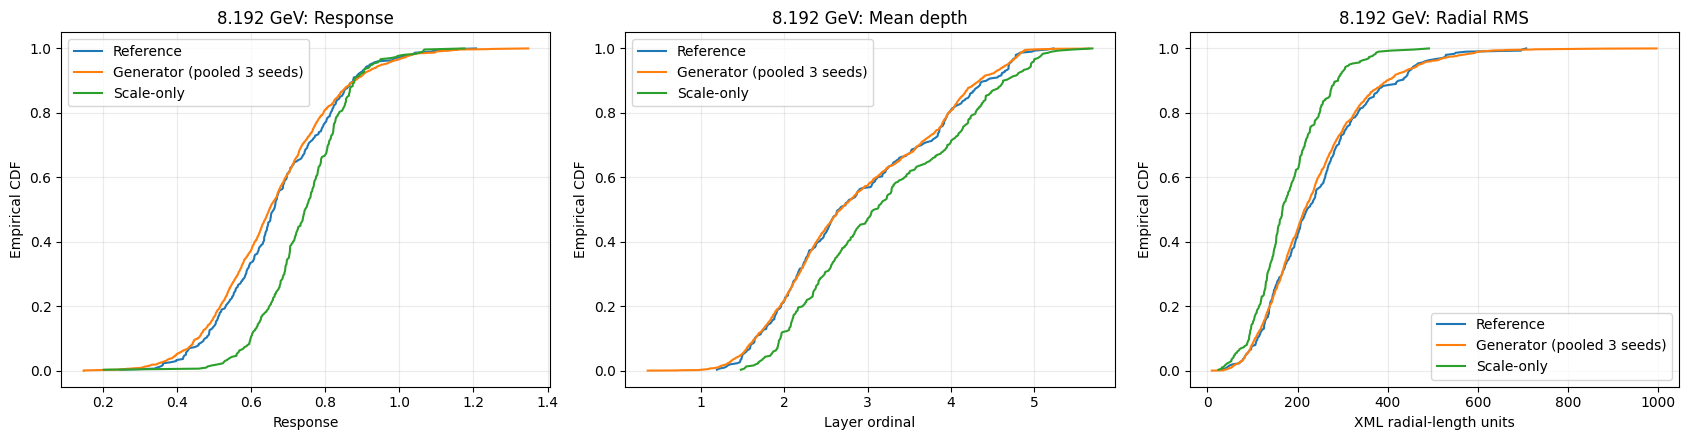

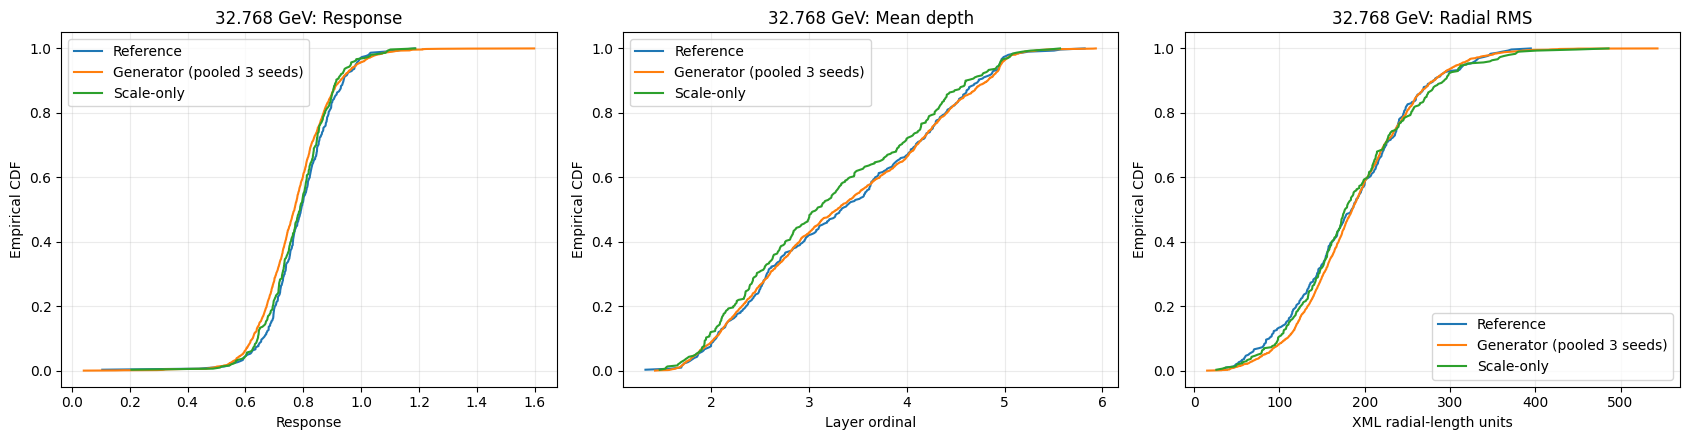

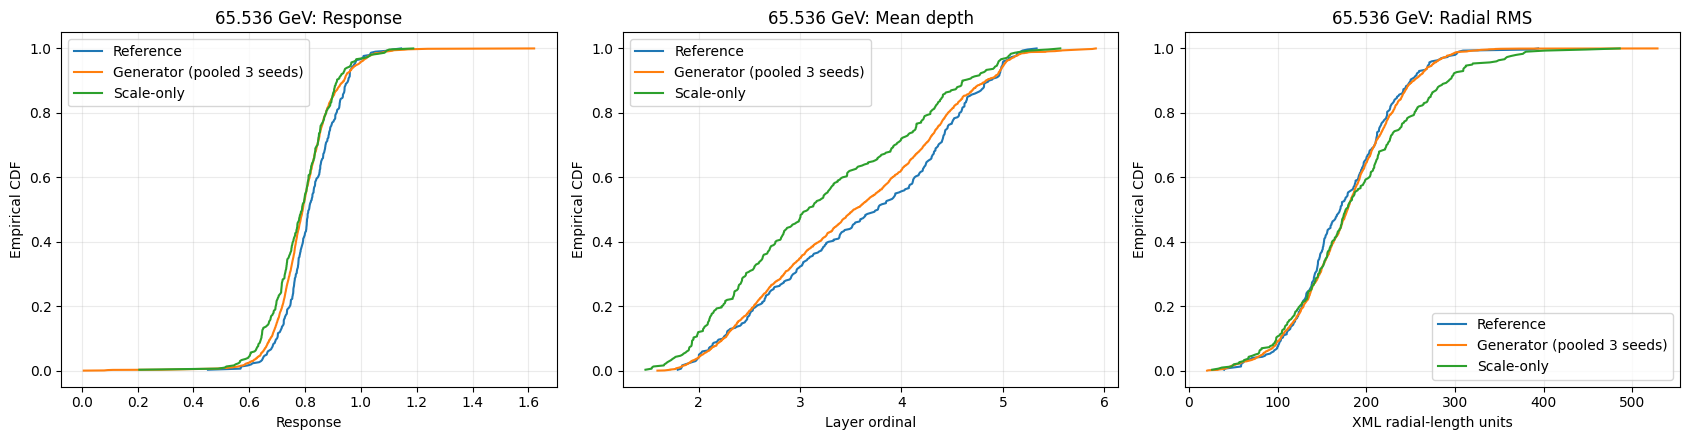

In [ ]:
plot_methods = [
    ("reference", "Reference"),
    ("generator", "Generator (pooled 3 seeds)"),
    ("scale_only", "Scale-only"),
]
for E in ENERGIES:
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    for method, label in plot_methods:
        if method == "generator":
            frame = event_metrics[(event_metrics.energy_GeV == E) & (event_metrics.method == method)]
        else:
            frame = event_metrics[(event_metrics.energy_GeV == E) & (event_metrics.method == method)]
        for ax, metric, xlabel in [
            (axes[0], "response", "Deposited / incident energy"),
            (axes[1], "depth_layer", "Energy-weighted active-layer ordinal"),
            (axes[2], "r_rms_XML", "Radial RMS (XML units)"),
        ]:
            x = np.sort(frame[metric].dropna().to_numpy())
            y = np.arange(1, len(x)+1) / len(x)
            ax.plot(x, y, label=label)
    axes[0].set_title(f"{E:g} GeV: Response")
    axes[1].set_title(f"{E:g} GeV: Mean depth")
    axes[2].set_title(f"{E:g} GeV: Radial RMS")
    for ax in axes:
        ax.set_ylabel("Empirical CDF")
        ax.grid(alpha=0.25)
        ax.legend()
    axes[0].set_xlabel("Response")
    axes[1].set_xlabel("Layer ordinal")
    axes[2].set_xlabel("XML radial-length units")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"pion_distribution_comparison_{E:.3f}GeV.png", dpi=160)
    plt.show()

## 19. Plot average longitudinal layer profiles

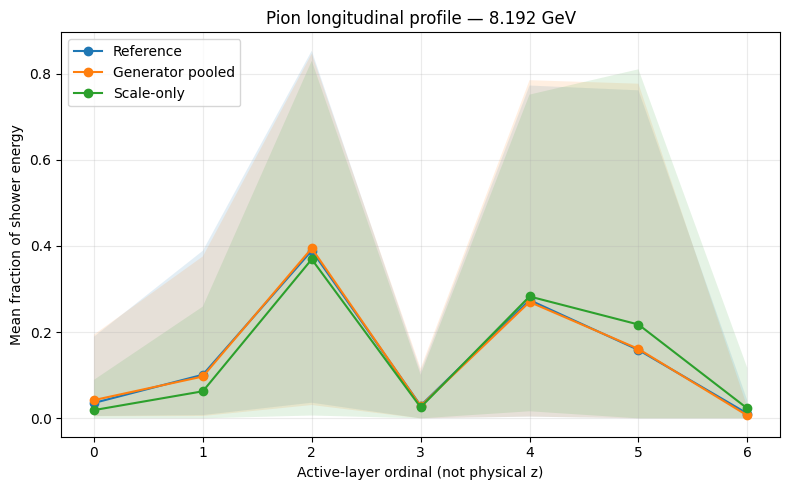

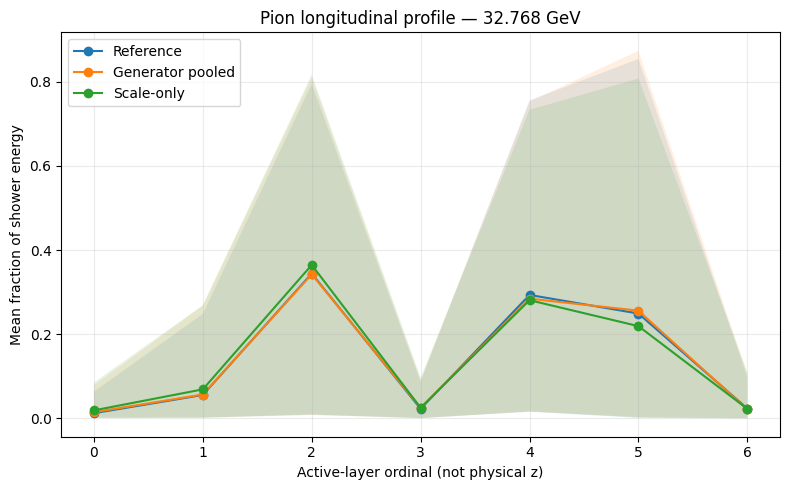

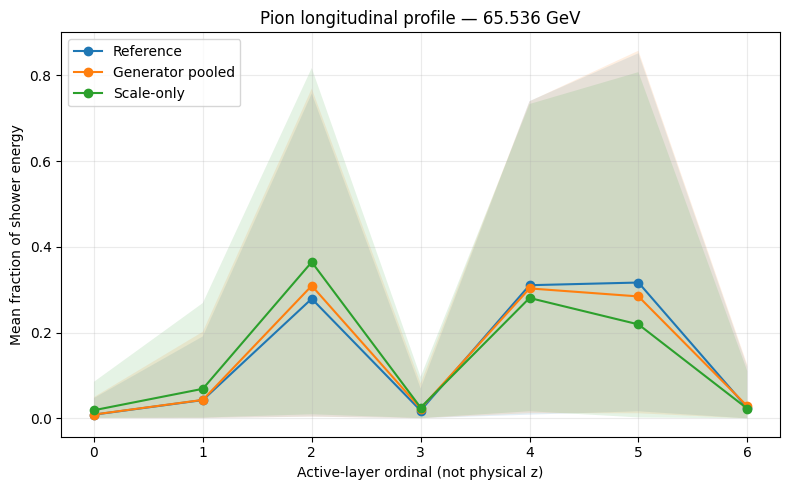

Layer-profile L1 distances (lower = closer):


,energy_GeV,method,seed,layer_profile_L1_from_reference
2,8.192,generator,20260110,0.046622
3,8.192,generator,20260111,0.052285
4,8.192,generator,20260112,0.047027
5,8.192,generator_pooled,pooled_3_seeds,0.028589
0,8.192,reference,reference,0.000000
1,8.192,scale_only,scale_only,0.158253
8,32.768,generator,20260110,0.049313
9,32.768,generator,20260111,0.027193
10,32.768,generator,20260112,0.027816
11,32.768,generator_pooled,pooled_3_seeds,0.025439


In [ ]:
for E in ENERGIES:
    fig, ax = plt.subplots(figsize=(8, 5))
    for method, label in [("reference", "Reference"), ("generator_pooled", "Generator pooled"), ("scale_only", "Scale-only")]:
        d = layer_profiles[(layer_profiles.energy_GeV == E) & (layer_profiles.method == method)].sort_values("layer_ordinal")
        x = d.layer_ordinal.to_numpy()
        y = d.mean_energy_fraction.to_numpy()
        ax.plot(x, y, marker="o", label=label)
        ax.fill_between(x, d.q05_event_fraction.to_numpy(), d.q95_event_fraction.to_numpy(), alpha=0.12)
    ax.set_title(f"Pion longitudinal profile — {E:g} GeV")
    ax.set_xlabel("Active-layer ordinal (not physical z)")
    ax.set_ylabel("Mean fraction of shower energy")
    ax.grid(alpha=0.25)
    ax.legend()
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"pion_layer_profile_{E:.3f}GeV.png", dpi=160)
    plt.show()

print("Layer-profile L1 distances (lower = closer):")
display(layer_profile_distances.sort_values(["energy_GeV", "method", "seed"]))

## 20. Plot common radial-band energy profiles

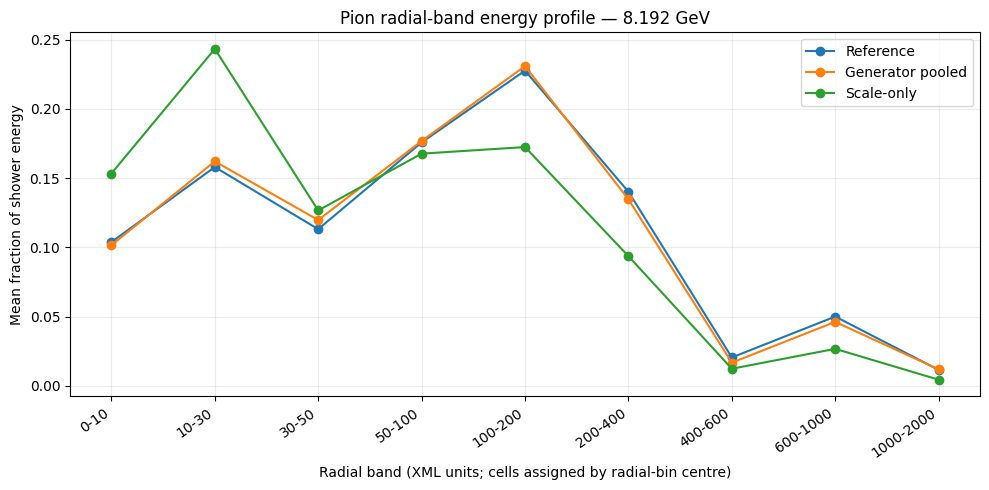

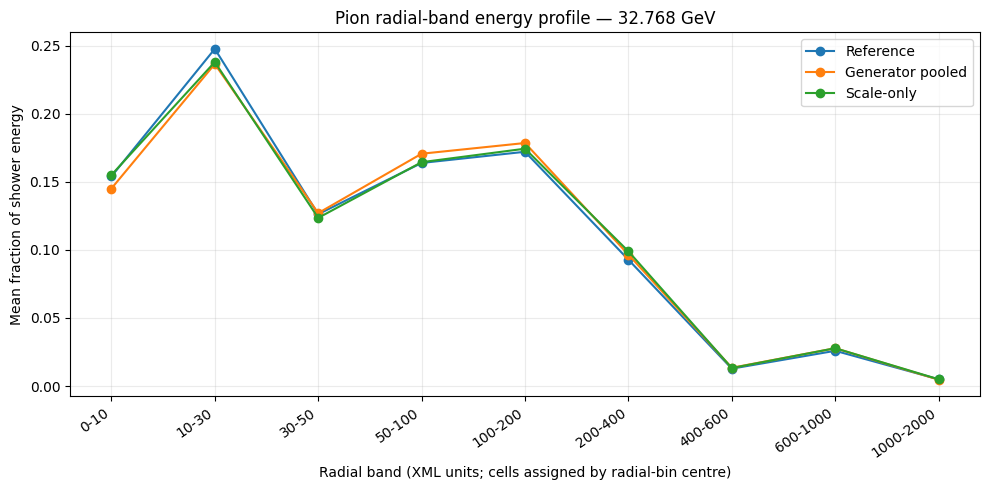

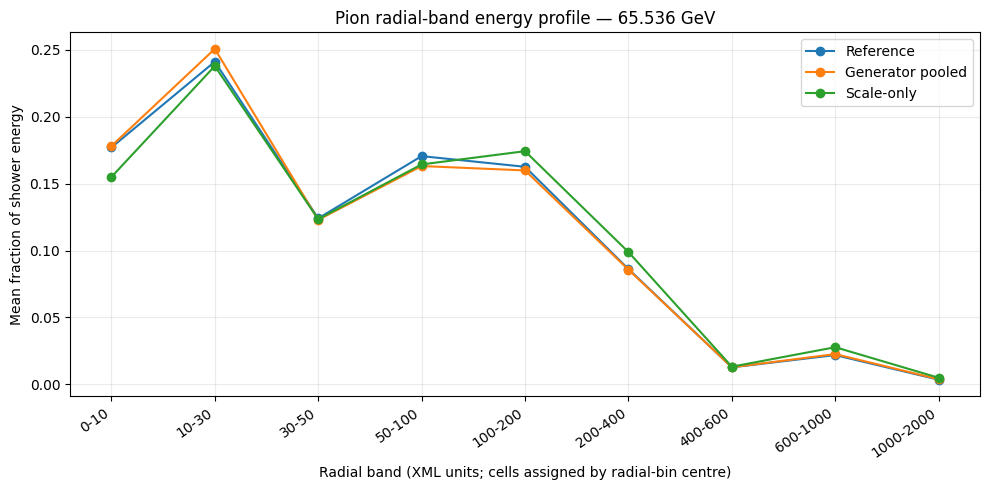

Radial-profile L1 distances (lower = closer):


,energy_GeV,method,seed,radial_profile_L1_from_reference
3,8.192,generator,20260110,0.020998
4,8.192,generator,20260111,0.045642
5,8.192,generator,20260112,0.029658
2,8.192,generator_pooled,pooled_3_seeds,0.030597
0,8.192,reference,reference,0.000000
1,8.192,scale_only,scale_only,0.296730
9,32.768,generator,20260110,0.040737
10,32.768,generator,20260111,0.024477
11,32.768,generator,20260112,0.058661
8,32.768,generator_pooled,pooled_3_seeds,0.040522


In [ ]:
for E in ENERGIES:
    fig, ax = plt.subplots(figsize=(10, 5))
    for method, label in [("reference", "Reference"), ("generator_pooled", "Generator pooled"), ("scale_only", "Scale-only")]:
        d = radial_profiles[(radial_profiles.energy_GeV == E) & (radial_profiles.method == method)]
        d = d.set_index("radial_band_XML").reindex(radial_band_labels).reset_index()
        ax.plot(np.arange(len(radial_band_labels)), d.mean_energy_fraction, marker="o", label=label)
    ax.set_xticks(np.arange(len(radial_band_labels)))
    ax.set_xticklabels(radial_band_labels, rotation=35, ha="right")
    ax.set_title(f"Pion radial-band energy profile — {E:g} GeV")
    ax.set_xlabel("Radial band (XML units; cells assigned by radial-bin centre)")
    ax.set_ylabel("Mean fraction of shower energy")
    ax.grid(alpha=0.25)
    ax.legend()
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"pion_radial_profile_{E:.3f}GeV.png", dpi=160)
    plt.show()

print("Radial-profile L1 distances (lower = closer):")
display(radial_profile_distances.sort_values(["energy_GeV", "method", "seed"]))

## 21. Layer × radial-band heatmaps

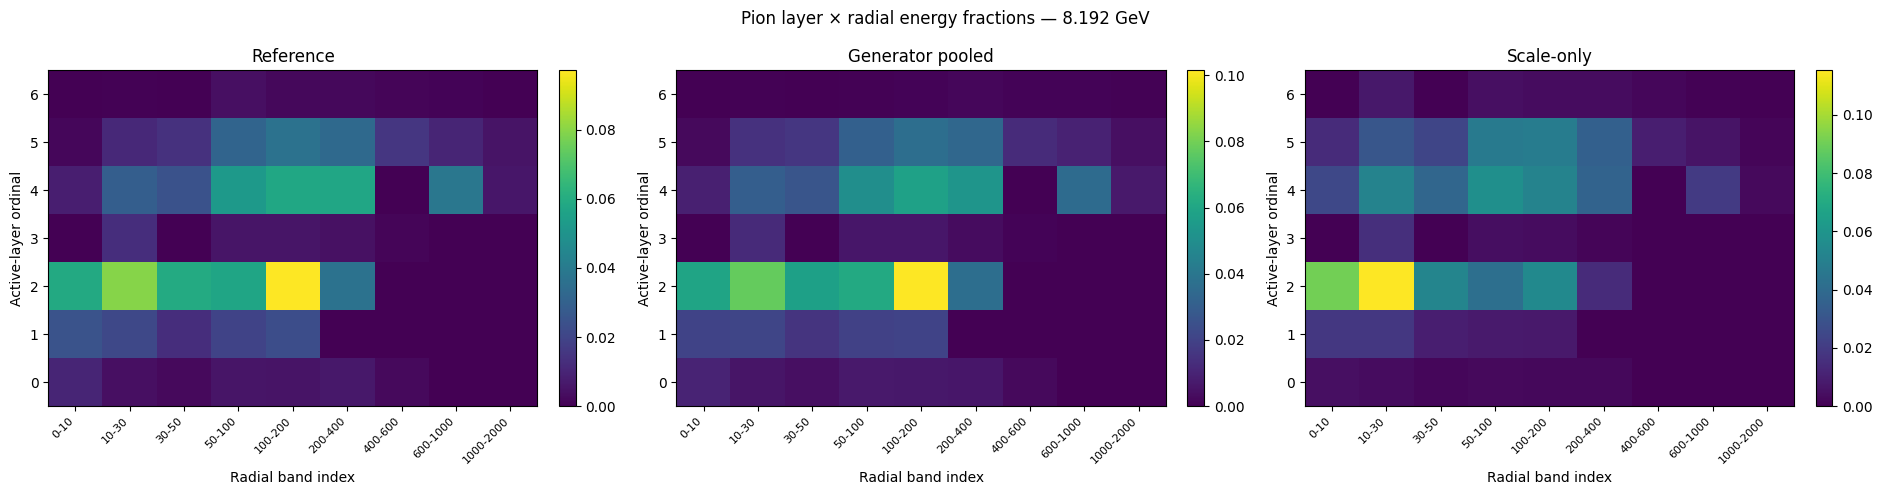

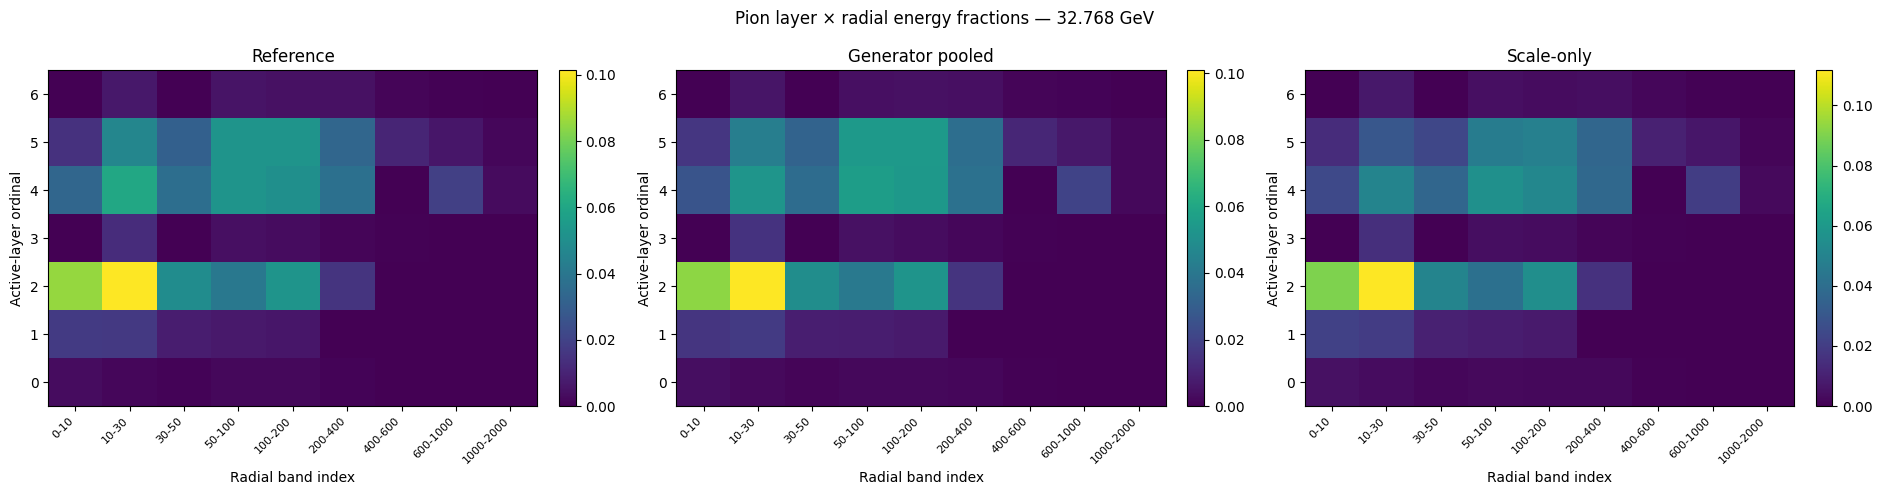

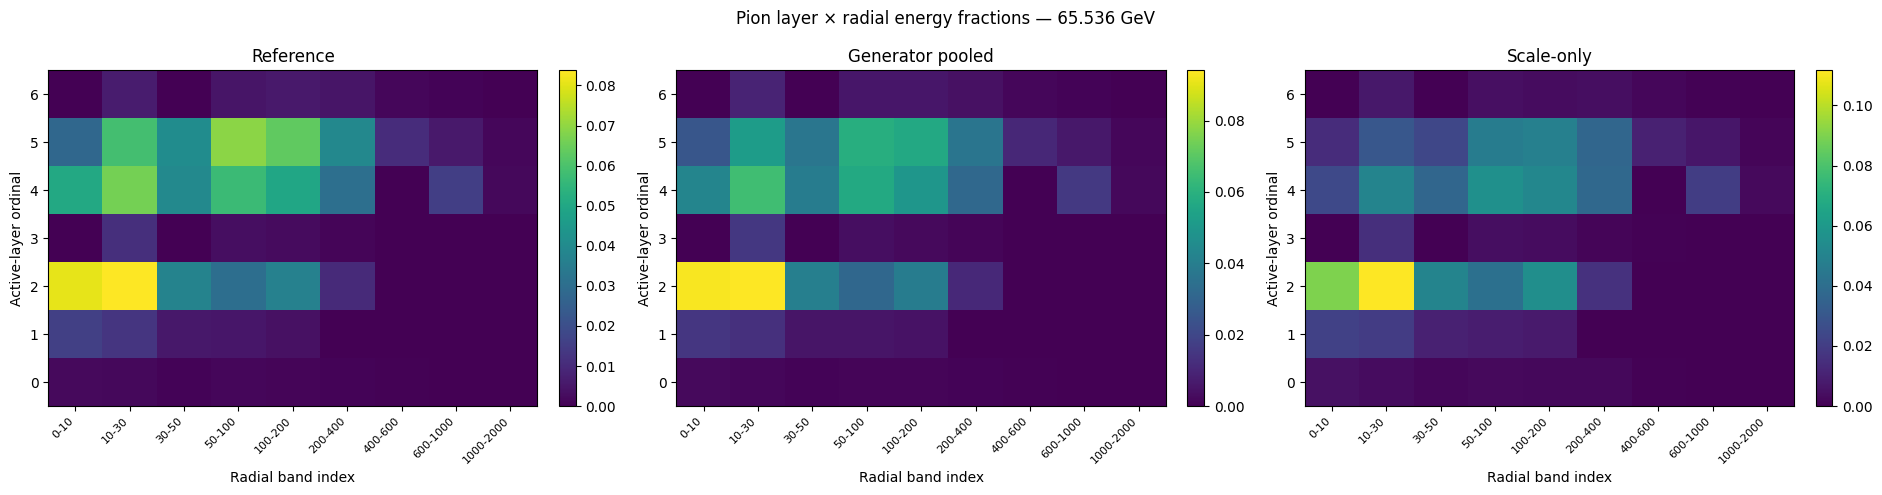

In [ ]:
# Heatmaps show where the average normalized shower energy is deposited.
for E in ENERGIES:
    fig, axes = plt.subplots(1, 3, figsize=(19, 5))
    for ax, method, title in zip(
        axes,
        ["reference", "generator", "scale_only"],
        ["Reference", "Generator pooled", "Scale-only"]
    ):
        # Calculate layer x radial band from the underlying retained arrays.
        if method == "generator":
            natives = np.concatenate([samples[(E, "generator", s)]["native"] for s in EXPECTED_SEEDS], axis=0)
        elif method == "reference":
            natives = samples[(E, "reference", "reference")]["native"]
        else:
            natives = samples[(E, "scale_only", "scale_only")]["native"]
        kept = np.where(np.isfinite(natives) & (natives >= ANALYSIS_CUT_GEV), natives, 0.0)
        total = kept.sum(axis=1)
        mats = []
        for j in range(len(layer_ids)):
            layer_mask = cell_layer_ord == j
            vals = np.column_stack([
                kept[:, layer_mask & (radial_band_ids == b)].sum(axis=1)
                for b in range(len(radial_band_labels))
            ])
            frac = np.divide(vals, total[:, None], out=np.zeros_like(vals), where=total[:, None] > 0)
            mats.append(frac.mean(axis=0))
        heat = np.vstack(mats)
        im = ax.imshow(heat, aspect="auto", origin="lower")
        ax.set_title(title)
        ax.set_xlabel("Radial band index")
        ax.set_ylabel("Active-layer ordinal")
        ax.set_xticks(range(len(radial_band_labels)))
        ax.set_xticklabels(radial_band_labels, rotation=45, ha="right", fontsize=8)
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    fig.suptitle(f"Pion layer × radial energy fractions — {E:g} GeV")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"pion_layer_radial_heatmaps_{E:.3f}GeV.png", dpi=160)
    plt.show()

## 22. Inspect representative candidate layer profiles

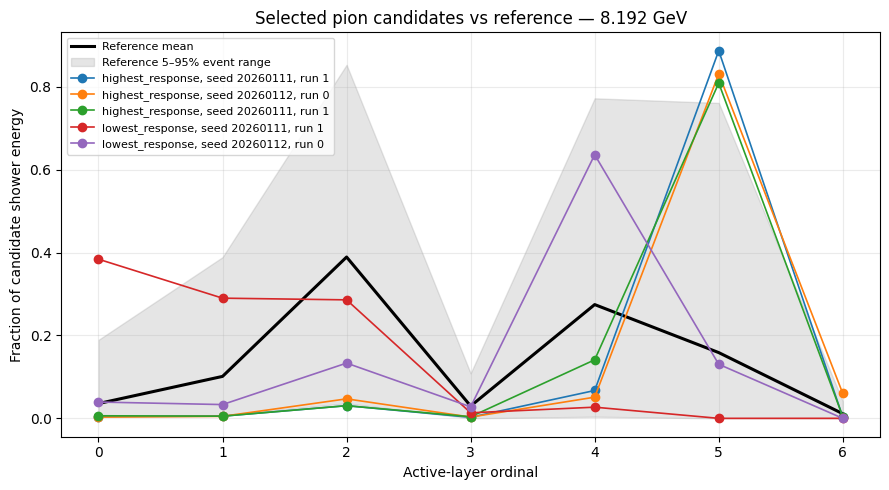

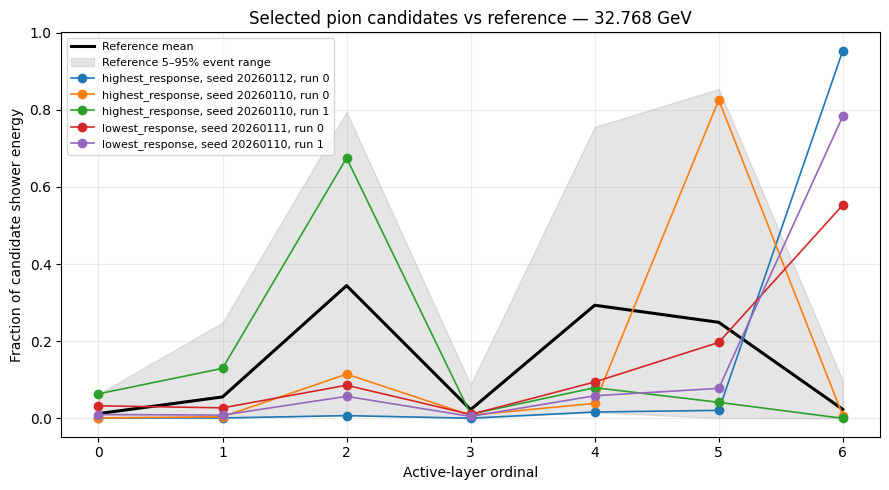

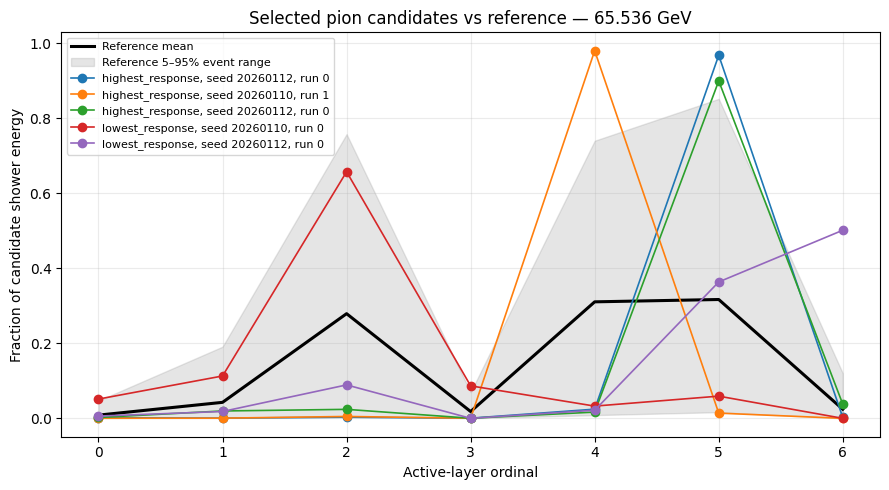

In [ ]:
# Plot up to five selected candidates per energy against the reference layer profile.
for E in ENERGIES:
    ref = event_metrics[(event_metrics.energy_GeV == E) & (event_metrics.method == "reference")]
    ref_mean = ref[layer_fraction_cols].mean().to_numpy()
    ref_lo = ref[layer_fraction_cols].quantile(0.05).to_numpy()
    ref_hi = ref[layer_fraction_cols].quantile(0.95).to_numpy()
    cands = selected_candidates[selected_candidates.energy_GeV == E].drop_duplicates("event_id").head(5)
    if len(cands) == 0:
        continue
    fig, ax = plt.subplots(figsize=(9, 5))
    x = np.arange(len(layer_ids))
    ax.plot(x, ref_mean, color="black", linewidth=2.2, label="Reference mean")
    ax.fill_between(x, ref_lo, ref_hi, color="gray", alpha=0.2, label="Reference 5–95% event range")
    for _, row in cands.iterrows():
        profile = np.array([row[f"layer_fraction_{j}"] for j in range(len(layer_ids))])
        label = f"{row.selection_category}, seed {row.seed}, run {row.generation_run}"
        ax.plot(x, profile, marker="o", linewidth=1.2, label=label)
    ax.set_title(f"Selected pion candidates vs reference — {E:g} GeV")
    ax.set_xlabel("Active-layer ordinal")
    ax.set_ylabel("Fraction of candidate shower energy")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"pion_candidate_profiles_{E:.3f}GeV.png", dpi=160)
    plt.show()

## 23. Response W1 comparison from the saved fidelity analysis

In [ ]:
w1_rows = []
for seed in EXPECTED_SEEDS:
    d = read_csv_member(runs[seed]["zip"], "tables/fidelity_distances.csv")
    d = d[(d.particle == "pion") & (d.observable.isin(["response", "occupancy", "depth_layer", "r_rms"])) & d.method.isin(["generator", "scale_only"])]
    d = d.copy()
    d["generation_seed"] = seed
    w1_rows.append(d)
w1_by_seed = pd.concat(w1_rows, ignore_index=True)
display(w1_by_seed[["generation_seed", "stratum", "method", "observable", "w1", "w1_lo", "w1_hi", "ks"]].sort_values(["stratum", "observable", "method", "generation_seed"]))

,generation_seed,stratum,method,observable,w1,w1_lo,w1_hi,ks
10,20260110,32.768GeV,generator,depth_layer,0.053626,0.051119,0.199077,0.048333
34,20260111,32.768GeV,generator,depth_layer,0.054824,0.051021,0.193373,0.046667
58,20260112,32.768GeV,generator,depth_layer,0.036359,0.051080,0.174568,0.028333
14,20260110,32.768GeV,scale_only,depth_layer,0.143646,0.064818,0.311870,0.090000
38,20260111,32.768GeV,scale_only,depth_layer,0.143646,0.064818,0.311870,0.090000
...,...,...,...,...,...,...,...,...
24,20260111,8.192GeV,generator,response,0.017959,0.012367,0.036157,0.060000
48,20260112,8.192GeV,generator,response,0.018592,0.011406,0.039993,0.076667
4,20260110,8.192GeV,scale_only,response,0.075368,0.057416,0.096692,0.303333
28,20260111,8.192GeV,scale_only,response,0.075368,0.057416,0.096692,0.303333


## 24. Export all tables, figures and an interpretation report

In [ ]:
# Core outputs
compatibility.to_csv(OUTPUT_DIR / "run_compatibility.csv", index=False)
event_metrics.to_csv(OUTPUT_DIR / "event_level_metrics_all_samples.csv", index=False)
outlier_candidates.to_csv(OUTPUT_DIR / "generator_reference_envelope_candidates.csv", index=False)
generator_robust.to_csv(OUTPUT_DIR / "generator_robust_z_screen.csv", index=False)
extreme_frequencies.to_csv(OUTPUT_DIR / "extreme_event_frequencies.csv", index=False)
summary.to_csv(OUTPUT_DIR / "event_metric_summary.csv", index=False)
layer_profiles.to_csv(OUTPUT_DIR / "layer_profiles.csv", index=False)
layer_profile_distances.to_csv(OUTPUT_DIR / "layer_profile_distances.csv", index=False)
radial_profiles.to_csv(OUTPUT_DIR / "radial_band_profiles.csv", index=False)
radial_profile_distances.to_csv(OUTPUT_DIR / "radial_profile_distances.csv", index=False)
cell_frequency.to_csv(OUTPUT_DIR / "native_cell_extreme_deposit_frequencies.csv", index=False)
cell_top.to_csv(OUTPUT_DIR / "top_recurring_native_cells.csv", index=False)
selected_candidates.to_csv(OUTPUT_DIR / "selected_candidate_events.csv", index=False)
candidate_top_cells.to_csv(OUTPUT_DIR / "selected_candidate_top_cells.csv", index=False)
w1_by_seed.to_csv(OUTPUT_DIR / "saved_fidelity_w1_by_seed.csv", index=False)
reconstruction_check.to_csv(OUTPUT_DIR / "native_array_reconstruction_check.csv", index=False)

# Compact markdown report
report = f"""# Pion Outlier and Layer-Profile Closeout\n\n- Generation seeds: {EXPECTED_SEEDS}\n- Energies: {ENERGIES} GeV\n- Analysis cutoff: {ANALYSIS_CUT_GEV} GeV\n- Native cells: {len(cell_map)}\n- Reference events: 300 per energy\n- Generated events: 600 per seed and energy (1,800 pooled per energy)\n- Checkpoint/reference/partition/donor compatibility: passed\n- Reference unseen by checkpoint: **not established**\n\n## Interpretation guidance\n\n- Reference q01–q99 flags are screening indicators, not physics-failure labels.\n- Robust-Z flags are complementary exploratory screens.\n- Fixed-cell recurrence uses diagnostic thresholds 0.1 and 1.0 GeV; these are not analysis cutoffs.\n- Radial-band profiles assign each native cell by its XML radial-bin centre to common bands; they are descriptive summaries of a geometry with layer-dependent native radial edges.\n- Scale-only donor showers originate from the 32.768 GeV donor sample and are rescaled to the other target energies.\n- No new generation, training or checkpoint update was performed.\n\n## Key files\n\nSee the CSV tables for seed-resolved statistics, event candidates, fixed-cell frequencies, layer and radial profiles, and W1 distances.\n"""
(OUTPUT_DIR / "pion_closeout_report.md").write_text(report)

zip_out = Path("/content/pion_outlier_layer_closeout_results.zip")
with zipfile.ZipFile(zip_out, "w", zipfile.ZIP_DEFLATED) as z:
    for path in OUTPUT_DIR.rglob("*"):
        if path.is_file():
            z.write(path, arcname=path.relative_to(OUTPUT_DIR))

print("Results saved:", zip_out)
print("Files:")
for p in sorted(OUTPUT_DIR.iterdir()):
    print(" -", p.name)
files.download(str(zip_out))

Results saved: /content/pion_outlier_layer_closeout_results.zip
Files:
 - event_level_metrics_all_samples.csv
 - event_metric_summary.csv
 - extreme_event_frequencies.csv
 - generator_reference_envelope_candidates.csv
 - generator_robust_z_screen.csv
 - layer_profile_distances.csv
 - layer_profiles.csv
 - native_array_reconstruction_check.csv
 - native_cell_extreme_deposit_frequencies.csv
 - pion_candidate_profiles_32.768GeV.png
 - pion_candidate_profiles_65.536GeV.png
 - pion_candidate_profiles_8.192GeV.png
 - pion_closeout_report.md
 - pion_distribution_comparison_32.768GeV.png
 - pion_distribution_comparison_65.536GeV.png
 - pion_distribution_comparison_8.192GeV.png
 - pion_layer_profile_32.768GeV.png
 - pion_layer_profile_65.536GeV.png
 - pion_layer_profile_8.192GeV.png
 - pion_layer_radial_heatmaps_32.768GeV.png
 - pion_layer_radial_heatmaps_65.536GeV.png
 - pion_layer_radial_heatmaps_8.192GeV.png
 - pion_radial_profile_32.768GeV.png
 - pion_radial_profile_65.536GeV.png
 - pion_ra

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 25. How to interpret the outputs

Focus on these files first:

1. `run_compatibility.csv` — confirms all three runs use the same reference, partition, checkpoint, cutoff and scale-only donors.
2. `event_metric_summary.csv` — response, occupancy, depth, radial RMS and maximum-cell statistics by seed.
3. `generator_reference_envelope_candidates.csv` — generated showers outside the reference q01–q99 screening envelope.
4. `extreme_event_frequencies.csv` — counts and Wilson intervals for unusual responses, depths, radial RMS and max-cell deposits.
5. `layer_profile_distances.csv` and `radial_profile_distances.csv` — shape differences relative to reference; lower L1 means closer average profile.
6. `top_recurring_native_cells.csv` — cells with repeated deposits at least 0.1 GeV; exploratory because many cells are inspected.
7. `selected_candidate_top_cells.csv` — largest cell deposits in representative candidate events.

**Do not delete or threshold away candidate showers.** Outlier flags are diagnostic only. Retain all generated events in fidelity results.

A final interpretation should distinguish (a) a population-level shift, (b) an unusually broad tail, and (c) a small number of isolated extreme showers. The 300-event reference sample limits precision in the far tails, and checkpoint/reference independence remains a separate provenance question.